# SL-PINN for 1D-1V Vlasov-Poisson: Gaussian advection

Production notebook for the Gaussian advection test (corresponging to the manuscript Section 4.2). A phase-space blob transported under its self-consistent field. We compare the learned inverse flow map (SL-PINN) against a a numerical (Strang splitting) reference solution, and against a vanilla Eulerian PINN. Functions are in `slpinn_gaussian1d.py`.

Flags below: `MODE` selects the SL-PINN map parameterisation; `SKIP_TRAINING`
reuses models saved under `outputs/` for post-processing only.

In [ ]:
import json
import time
from pathlib import Path

import matplotlib
try:
    get_ipython  # noqa: F821
except NameError:
    matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import torch

import slpinn_gaussian1d as sl

MODE = "symplectic"        # "symplectic" | "normalizing" | "soft"
SKIP_TRAINING = True      # True: load saved models from outputs/ and only plot
QUICK = False               # True: minutes on GPU; False: paper-scale settings


DEVICE = "cuda"     #  "cpu" | "cuda"
device = torch.device(DEVICE)
dtype = sl.default_dtype(device)
torch.manual_seed(0)

OUT = Path("outputs")
OUT.mkdir(exist_ok=True)
SL_PATH = OUT / f"gaussian_sl_{MODE}.pt"
VAN_PATH = OUT / "gaussian_vanilla.pt"

if QUICK:
    SL_ITERS, VAN_ITERS, FIELD_N, EVAL_NX, EVAL_NV = 750, 1500, 64, 128, 128
else:
    SL_ITERS, VAN_ITERS, FIELD_N, EVAL_NX, EVAL_NV = 1500, 3000, 64, 256, 256

print(f"mode={MODE}  skip_training={SKIP_TRAINING}  quick={QUICK}  device={device}")

mode=symplectic  skip_training=True  quick=False  device=cpu


## SL-PINN (train or load)

In [12]:
if SKIP_TRAINING:
    assert SL_PATH.exists(), f"missing {SL_PATH}; run once with SKIP_TRAINING=False"
    model, problem, f_fn, cfg = sl.load_model(SL_PATH, device=str(device))
    print(f"loaded {SL_PATH}")
else:
    cfg = sl.TrainConfig(problem="gaussian_vp", mode=MODE, iters=SL_ITERS,
                         field_nx=FIELD_N, field_nv=FIELD_N, 
                         sampling="support",
                        gating="linear", normalize_inputs=False,
                         log_every=50, n_per_slice=516,
                         device=str(device))
    trainer = sl.Trainer(cfg)
    trainer.train()
    trainer.save(SL_PATH)
    model, problem, f_fn = trainer.model, trainer.problem, trainer.f_fn
    print(f"saved {SL_PATH}  ({sl.n_params(model)} params, {trainer.train_time:.1f}s)")

det_rows = sl.det_statistics(model, problem,
                             torch.linspace(0, problem.t_final, 3, device=device, dtype=dtype),
                             n_points=512)
print("max |det - 1| over t:", max(r["max"] for r in det_rows))

loaded outputs/gaussian_sl_symplectic.pt
max |det - 1| over t: 1.7763568394002505e-15


## Vanilla PINN (train or load)

A plain Eulerian network `f = f_theta(t, x, v)` trained on the transport
residual with the initial and boundary conditions as soft penalties.

In [13]:
if SKIP_TRAINING:
    assert VAN_PATH.exists(), f"missing {VAN_PATH}; run once with SKIP_TRAINING=False"
    van_model, _, van_f_fn, van_cfg = sl.load_vanilla(VAN_PATH, device=str(device))
    print(f"loaded {VAN_PATH}")
else:
    van_cfg = sl.VanillaConfig(problem="gaussian_vp", iters=VAN_ITERS,
                               field_nx=FIELD_N, field_nv=FIELD_N,
                               device=str(device))
    van_trainer = sl.VanillaTrainer(van_cfg)
    van_trainer.train()
    van_trainer.save(VAN_PATH)
    van_model, van_f_fn = van_trainer.model, van_trainer.f_fn
    print(f"saved {VAN_PATH}  ({sl.n_params(van_model)} params, {van_trainer.train_time:.1f}s)")

loaded outputs/gaussian_vanilla.pt


## Reference solution

Spectral semi-Lagrangian solver (Strang splitting, exact FFT sub-steps, double
precision) on an N^2 grid, at the plot times.

In [14]:
times = torch.tensor(problem.plot_times, device=device, dtype=dtype)   # [0,0.5,1,1.5,2]
f_ref, xg, vg = sl.reference_on_grid(problem, times, EVAL_NX, EVAL_NV,
                                     OUT, device, dtype, verbose=True)
f_sl = sl.evaluate_f_on_grid(f_fn, times, xg, vg)
f_van = sl.evaluate_f_on_grid(van_f_fn, times, xg, vg)
tvals = times.tolist()
print("reference grid:", tuple(f_ref.shape))


def tidx(t):
    return min(range(len(tvals)), key=lambda i: abs(tvals[i] - t))


def save_fig(fig, name):
    for ext in ("png", "pdf"):
        fig.savefig(OUT / f"{name}.{ext}")

reference grid: (5, 256, 256)


## Figure 1 - phase space

The distribution at t=0,1,2: reference (NUM), SL-PINN, and their difference.

| t | l2 | linf | rel_l2 |
|---|---|---|---|
| 0 | 3.195e-09 | 2.98e-08 | 5.422e-08 |
| 0.5 | 0.0002057 | 0.001483 | 0.00349 |
| 1 | 0.0002605 | 0.001866 | 0.004422 |
| 1.5 | 0.0003762 | 0.003421 | 0.006384 |
| 2 | 0.0005101 | 0.0048 | 0.008657 |


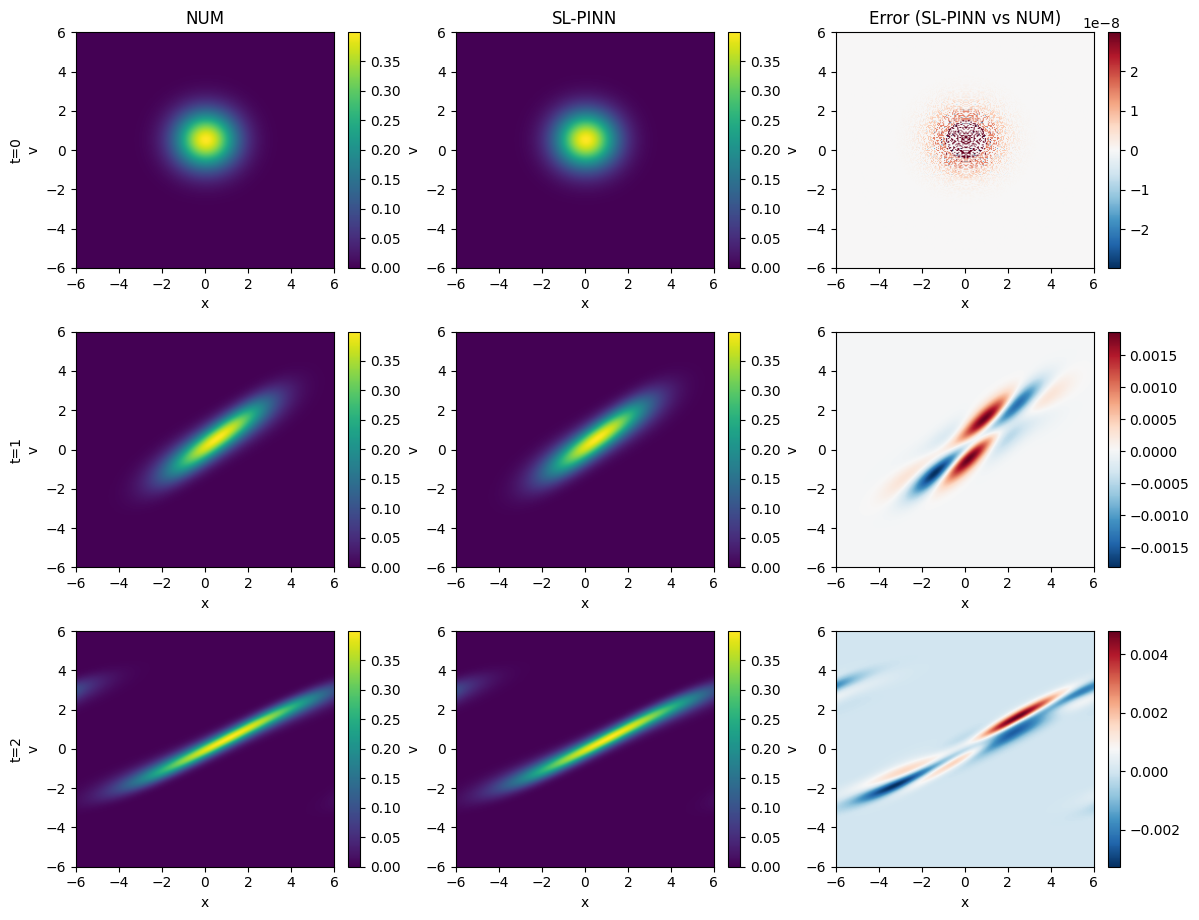

In [15]:
rows_err = sl.error_table(f_sl, f_ref, times)
print(sl.markdown_table(rows_err, columns=["t", "l2", "linf", "rel_l2"]))

sel = [tidx(0.0), tidx(1.0), tidx(2.0)]
ext = [problem.x_lo, problem.x_hi, problem.v_lo, problem.v_hi]
fig, axes = plt.subplots(len(sel), 3, figsize=(12, 3.1 * len(sel)))
for r, i in enumerate(sel):
    vmax = float(f_ref[i].max())
    for ax, (data, title, cmap, kw) in zip(axes[r], [
            (f_ref[i], "NUM", "viridis", dict(vmin=0, vmax=vmax)),
            (f_sl[i], "SL-PINN", "viridis", dict(vmin=0, vmax=vmax)),
            (f_sl[i] - f_ref[i], "Error (SL-PINN vs NUM)", "RdBu_r", dict())]):
        im = ax.imshow(data.T.cpu(), origin="lower", extent=ext, aspect="auto",
                       cmap=cmap, **kw)
        fig.colorbar(im, ax=ax, fraction=0.046)
        if r == 0:
            ax.set_title(title)
        ax.set_xlabel("x"); ax.set_ylabel("v"); ax.grid(False)
    axes[r][0].set_ylabel(f"t={tvals[i]:g}\nv")
fig.tight_layout()
save_fig(fig, "fig1_phase_space")
plt.show()

## Figure 2 - evolution of f over x and over v

Cross-sections of f along x (at the initial velocity slice) and along v (at
x=0) at t=0,0.5,1,1.5,2. NUM solid, SL-PINN dashed.

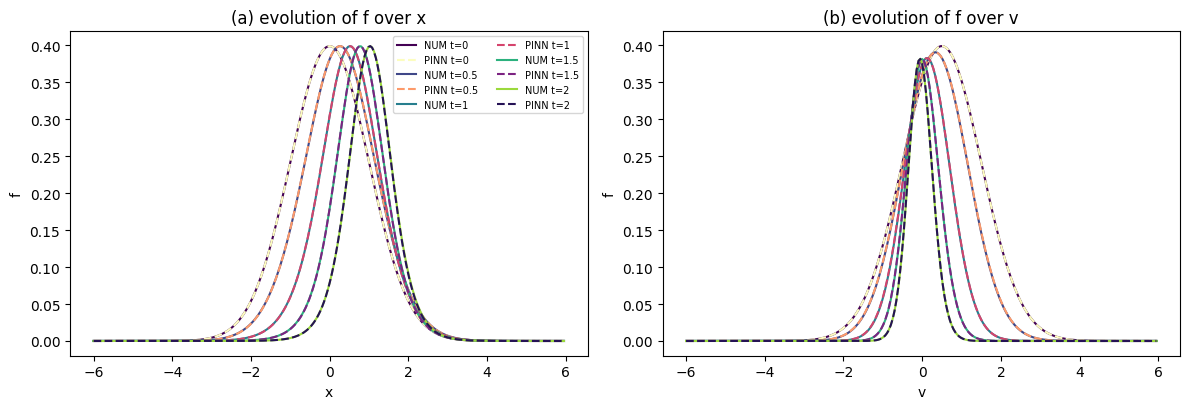

In [16]:
iv = int(f_ref[0].sum(0).argmax())   # v-index of the peak
ix = int(f_ref[0].sum(1).argmax())                               # x-index of the peak
colors = plt.cm.viridis(np.linspace(0, 0.85, len(tvals)))
colors_p = plt.cm.magma_r(np.linspace(0, 0.85, len(tvals)))
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2))
for i, t in enumerate(tvals):
    ax1.plot(xg.cpu(), f_ref[i, :, iv].cpu(), "-", color=colors[i], lw=1.5,
             label=f"NUM t={t:g}")
    ax1.plot(xg.cpu(), f_sl[i, :, iv].cpu(), "--", color=colors_p[i], lw=1.5,
             label=f"PINN t={t:g}")
    ax2.plot(vg.cpu(), f_ref[i, ix, :].cpu(), "-", color=colors[i], lw=1.5)
    ax2.plot(vg.cpu(), f_sl[i, ix, :].cpu(), "--", color=colors_p[i], lw=1.5)
ax1.set_xlabel("x"); ax1.set_ylabel("f"); ax1.set_title("(a) evolution of f over x")
ax2.set_xlabel("v"); ax2.set_ylabel("f"); ax2.set_title("(b) evolution of f over v")
ax1.legend(fontsize=7, ncol=2)
fig.tight_layout()
save_fig(fig, "fig2_slices")
plt.show()

## Figure 3 - charge density and electric field

rho(x) = integral f dv and E(x) at t=0,0.5,1,1.5,2. NUM solid, SL-PINN dashed.

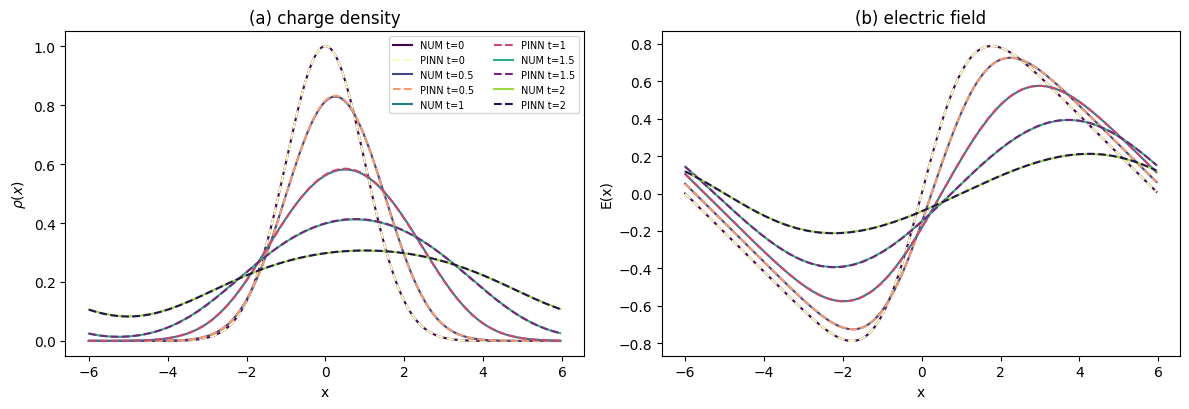

In [17]:
wv = sl.trapezoid_weights(vg)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2))
for i, t in enumerate(tvals):
    rho_r = torch.einsum("xv,v->x", f_ref[i], wv)
    rho_s = torch.einsum("xv,v->x", f_sl[i], wv)
    ax1.plot(xg.cpu(), rho_r.cpu(), "-", color=colors[i], lw=1.5, label=f"NUM t={t:g}")
    ax1.plot(xg.cpu(), rho_s.cpu(), "--", color=colors_p[i], lw=1.5, label=f"PINN t={t:g}")
    ax2.plot(xg.cpu(), sl.electric_field(rho_r, problem.length).cpu(), "-",
             color=colors[i], lw=1.5)
    ax2.plot(xg.cpu(), sl.electric_field(rho_s, problem.length).cpu(), "--",
             color=colors_p[i], lw=1.5)
ax1.set_xlabel("x"); ax1.set_ylabel(r"$\rho(x)$"); ax1.set_title("(a) charge density")
ax2.set_xlabel("x"); ax2.set_ylabel("E(x)"); ax2.set_title("(b) electric field")
ax1.legend(fontsize=7, ncol=2)
fig.tight_layout()
save_fig(fig, "fig3_rho_E")
plt.show()

## Figure 4 - characteristics

Particle trajectories x(t), v(t) and the phase portrait v(x), for nine
particles released from rest. NUM = reference field integration; SL-PINN =
the learned inverse map.

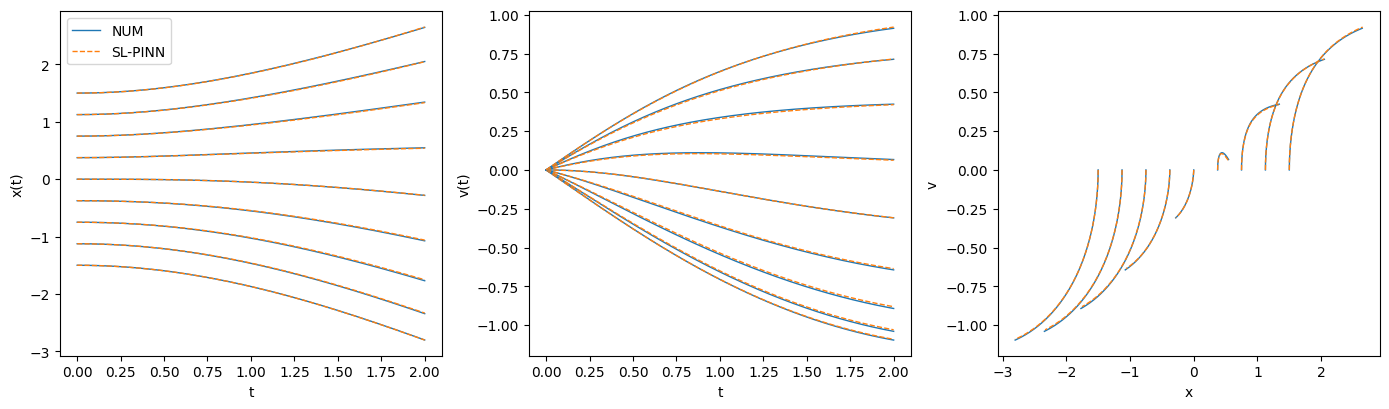

In [18]:
x0 = torch.linspace(-1.5, 1.5, 9, dtype=dtype)
z0 = torch.stack([x0, torch.zeros_like(x0)], dim=-1)
t_ref, traj_ref = sl.characteristics_reference(problem, z0, dt=1 / 128,
                                               nx=EVAL_NX, nv=EVAL_NV, device=str(device))
sub = max(1, len(t_ref) // 200)
t_sub = t_ref[::sub]
traj_sl = sl.characteristics_map(model, z0, t_sub.to(device))
tt = t_sub.cpu().numpy()
tr_r = traj_ref[::sub].cpu().numpy()
tr_s = traj_sl.cpu().numpy()

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(14, 4.2))
for j in range(z0.shape[0]):
    ax1.plot(tt, tr_r[:, j, 0], "-", color="C0", lw=1, label="NUM" if j == 0 else None)
    ax1.plot(tt, tr_s[:, j, 0], "--", color="C1", lw=1, label="SL-PINN" if j == 0 else None)
    ax2.plot(tt, tr_r[:, j, 1], "-", color="C0", lw=1)
    ax2.plot(tt, tr_s[:, j, 1], "--", color="C1", lw=1)
    ax3.plot(tr_r[:, j, 0], tr_r[:, j, 1], "-", color="C0", lw=1)
    ax3.plot(tr_s[:, j, 0], tr_s[:, j, 1], "--", color="C1", lw=1)
ax1.set_xlabel("t"); ax1.set_ylabel("x(t)"); ax1.legend()
ax2.set_xlabel("t"); ax2.set_ylabel("v(t)")
ax3.set_xlabel("x"); ax3.set_ylabel("v")
fig.tight_layout()
save_fig(fig, "fig4_characteristics")
plt.show()

## Figure 5 - SL-PINN vs vanilla PINN

Charge density and electric field at t=0 and t=0.5 for the numerical solution,
the SL-PINN, and the vanilla Eulerian PINN.

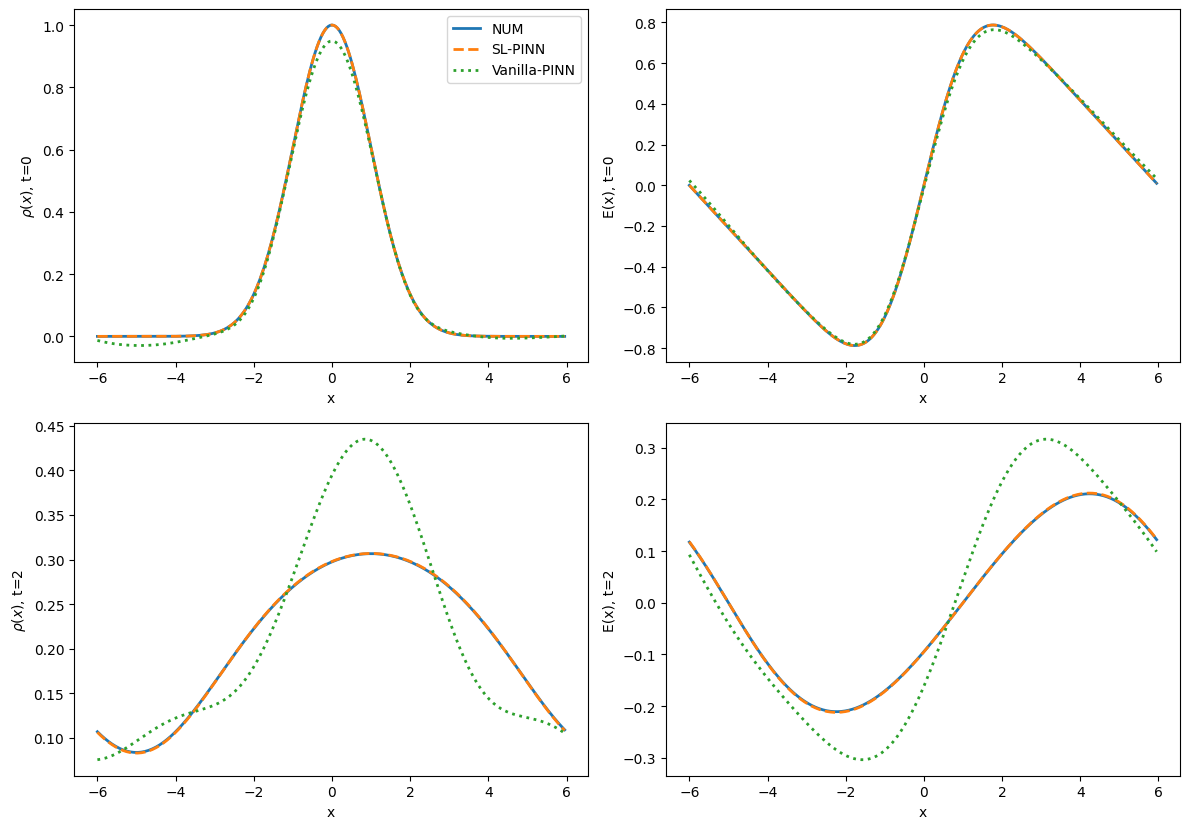

figures written to outputs


In [19]:
sel5 = [tidx(0.0), tidx(2.)]
fig, axes = plt.subplots(len(sel5), 2, figsize=(12, 4.2 * len(sel5)))
for r, i in enumerate(sel5):
    t = tvals[i]
    rho_r = torch.einsum("xv,v->x", f_ref[i], wv)
    rho_s = torch.einsum("xv,v->x", f_sl[i], wv)
    rho_v = torch.einsum("xv,v->x", f_van[i], wv)
    axes[r][0].plot(xg.cpu(), rho_r.cpu(), "-", lw=2, label="NUM")
    axes[r][0].plot(xg.cpu(), rho_s.cpu(), "--", lw=2, label="SL-PINN")
    axes[r][0].plot(xg.cpu(), rho_v.cpu(), ":", lw=2, label="Vanilla-PINN")
    axes[r][1].plot(xg.cpu(), sl.electric_field(rho_r, problem.length).cpu(), "-", lw=2)
    axes[r][1].plot(xg.cpu(), sl.electric_field(rho_s, problem.length).cpu(), "--", lw=2)
    axes[r][1].plot(xg.cpu(), sl.electric_field(rho_v, problem.length).cpu(), ":", lw=2)
    axes[r][0].set_ylabel(fr"$\rho(x)$, t={t:g}"); axes[r][0].set_xlabel("x")
    axes[r][1].set_ylabel(f"E(x), t={t:g}"); axes[r][1].set_xlabel("x")
axes[0][0].legend()
fig.tight_layout()
save_fig(fig, "fig5_vanilla_comparison")
plt.show()

print("figures written to", OUT)

## Transport along the characteristics

Samples of `f0` at t=0 (plasma) carried to t=T by the learned
inverse map: each point moves along `z(t) = Psi^{-1}(t, z0)`, and `f` is constant
along that curve. A few tracer characteristics are drawn in full, coloured by their initial velocity;
x is periodic, so the lines are cut where they wrap around the box.

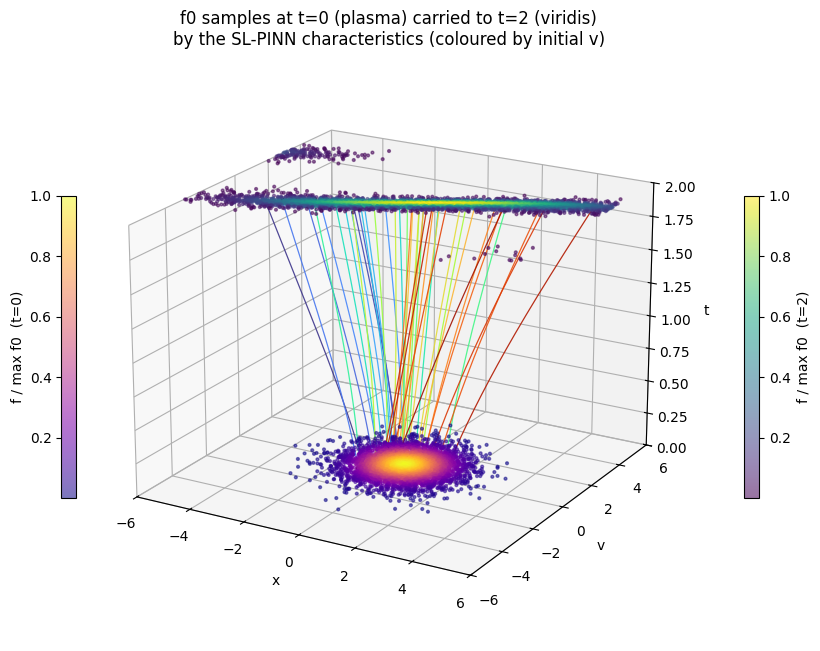

In [20]:
# 3D view of the transport: f0 samples at t=0 pushed to t=T along the
# characteristics of the learned map (f is constant along each curve).
N_CLOUD, N_TRAJ, N_TIME = 4000, 40, 201
T_FIN = problem.t_final
L = problem.length


def wrap_x(x):
    return torch.remainder(x - problem.x_lo, L) + problem.x_lo


g = torch.Generator().manual_seed(1)
z0_cloud = torch.stack([torch.randn(N_CLOUD, generator=g, dtype=dtype),
                        0.5 + torch.randn(N_CLOUD, generator=g, dtype=dtype)], dim=-1)
w0 = problem.f0(z0_cloud)
w0n = (w0 / w0.max()).numpy()

t_line = torch.linspace(0.0, T_FIN, N_TIME, dtype=dtype)
zT_cloud = sl.characteristics_map(model, z0_cloud, t_line[-1:].to(device))[0].cpu()

# tracer characteristics drawn from the bulk of f0, ordered by initial velocity
idx = torch.multinomial(w0, N_TRAJ, replacement=False, generator=g)
idx = idx[z0_cloud[idx, 1].argsort()]
traj = sl.characteristics_map(model, z0_cloud[idx], t_line.to(device)).cpu()
tx = wrap_x(traj[..., 0]).numpy()
tv = traj[..., 1].numpy()
tt = np.repeat(t_line.numpy()[:, None], N_TRAJ, axis=1)
tx[:-1][np.abs(np.diff(tx, axis=0)) > 0.5 * L] = np.nan   # break lines at the wrap

fig = plt.figure(figsize=(9.5, 7.5))
ax = fig.add_subplot(111, projection="3d")
sc0 = ax.scatter(wrap_x(z0_cloud[:, 0]), z0_cloud[:, 1], np.zeros(N_CLOUD), c=w0n,
                 cmap="plasma", s=4, alpha=0.55, depthshade=False)
scT = ax.scatter(wrap_x(zT_cloud[:, 0]), zT_cloud[:, 1], np.full(N_CLOUD, T_FIN), c=w0n,
                 cmap="viridis", s=4, alpha=0.55, depthshade=False)
cols = plt.cm.turbo(np.linspace(0.05, 0.95, N_TRAJ))
for j in range(N_TRAJ):
    ax.plot(tx[:, j], tv[:, j], tt[:, j], color=cols[j], lw=0.9, alpha=0.9)
ax.scatter(tx[0], tv[0], 0.0, c="k", s=9, depthshade=False)
ax.scatter(tx[-1], tv[-1], T_FIN, c="k", s=9, depthshade=False)

ax.set_xlabel("x"); ax.set_ylabel("v"); ax.set_zlabel("t")
ax.set_xlim(problem.x_lo, problem.x_hi)
ax.set_ylim(problem.v_lo, problem.v_hi)
ax.set_zlim(0.0, T_FIN)
ax.view_init(elev=20, azim=-60)
ax.set_title(f"f0 samples at t=0 (plasma) carried to t={T_FIN:g} (viridis)\n"
             "by the SL-PINN characteristics (coloured by initial v)")
fig.colorbar(sc0, ax=ax, shrink=0.42, pad=0.02, location="left").set_label("f / max f0  (t=0)")
fig.colorbar(scT, ax=ax, shrink=0.42, pad=0.08).set_label(f"f / max f0  (t={T_FIN:g})")
fig.tight_layout()
save_fig(fig, "fig8_characteristic_transport")
plt.show()